
# Marketing A/B Testing: Conversion Analysis & Business Decision-Making

**Analyst:** Azizul Hakim  
**Project Type:** Independent Data Analytics Portfolio Project  
**Dataset:** [Marketing A/B Testing - Kaggle](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing)  
**Tools:** Python, Pandas, NumPy, Statsmodels, Matplotlib

---

## Business Problem

Does product advertising achieve a higher conversion rate than a Public Service Announcement (PSA)?

This project analyses 588,101 user records to evaluate advertising performance, test statistical significance, and recommend evidence-based business decisions.

## Project Objectives

1. Compare conversion rates between Ad and PSA groups.
2. Calculate absolute and relative conversion lift.
3. Evaluate statistical significance using a two-proportion Z-test.
4. Estimate a 95% confidence interval.
5. Assess data quality and experiment limitations.
6. Recommend appropriate business actions based on the results.

## Key Results

| Metric | Result |
|---|---:|
| Users Analysed | 588,101 |
| Ad Conversion Rate | 2.5547% |
| PSA Conversion Rate | 1.7854% |
| Relative Conversion Lift | +43.09% |
| P-value | 1.705 × 10^-13 |
| 95% CI for Difference | +0.5873 to +0.9360 pp |

## Business Recommendation

**Decision: Validate Before Scaling**

The Ad group demonstrated a statistically significant higher conversion rate. However, experiment randomisation, planned group allocation, and campaign profitability must be verified before increasing advertising investment.

---

## Analysis and Implementation



## 1. Data Loading and Inspection

In [1]:

import pandas as pd
from pathlib import Path

# Find the marketing A/B testing CSV
files = list(Path("/kaggle/input").rglob("marketing_AB.csv"))

if not files:
    raise FileNotFoundError("Dataset not found. Add Marketing A/B Testing under Input.")

df = pd.read_csv(files[0])

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

df.head()


Total Rows: 588101
Total Columns: 7


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 2. Data Cleaning and Validation

In [2]:

# BLOCK 2: DATA CLEANING & QUALITY CHECK

# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

# 1. Dataset shape
print("Dataset Shape:", df.shape)

# 2. Missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 3. Duplicate user IDs
print("\n--- Duplicate User IDs ---")
print(df["user id"].duplicated().sum())

# 4. Test group distribution
print("\n--- Test Group Distribution ---")
print(df["test group"].value_counts())

# 5. Conversion distribution
print("\n--- Conversion Distribution ---")
print(df["converted"].value_counts())

# 6. Column data types
print("\n--- Data Types ---")
print(df.dtypes)


Dataset Shape: (588101, 6)

--- Missing Values ---
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

--- Duplicate User IDs ---
0

--- Test Group Distribution ---
test group
ad     564577
psa     23524
Name: count, dtype: int64

--- Conversion Distribution ---
converted
False    573258
True      14843
Name: count, dtype: int64

--- Data Types ---
user id           int64
test group       object
converted          bool
total ads         int64
most ads day     object
most ads hour     int64
dtype: object


## 3. Conversion Rate Analysis

In [3]:

# BLOCK 3: CONVERSION RATE & LIFT ANALYSIS

# Calculate group-wise performance
group_summary = df.groupby("test group").agg(
    total_users=("user id", "count"),
    conversions=("converted", "sum")
)

# Calculate conversion rate
group_summary["conversion_rate"] = (
    group_summary["conversions"] /
    group_summary["total_users"]
)

# Show percentages
group_summary["conversion_rate_pct"] = (
    group_summary["conversion_rate"] * 100
)

print("=== GROUP-WISE CONVERSION PERFORMANCE ===")
print(group_summary.round(4))

# Extract conversion rates
ad_rate = group_summary.loc["ad", "conversion_rate"]
psa_rate = group_summary.loc["psa", "conversion_rate"]

# Absolute difference in percentage points
absolute_difference = (ad_rate - psa_rate) * 100

# Relative conversion lift
relative_lift = ((ad_rate - psa_rate) / psa_rate) * 100

print("\n=== A/B TEST RESULTS ===")
print(f"Ad Conversion Rate: {ad_rate * 100:.4f}%")
print(f"PSA Conversion Rate: {psa_rate * 100:.4f}%")
print(f"Absolute Difference: {absolute_difference:+.4f} percentage points")
print(f"Relative Conversion Lift: {relative_lift:+.2f}%")


=== GROUP-WISE CONVERSION PERFORMANCE ===
            total_users  conversions  conversion_rate  conversion_rate_pct
test group                                                                
ad               564577        14423           0.0255               2.5547
psa               23524          420           0.0179               1.7854

=== A/B TEST RESULTS ===
Ad Conversion Rate: 2.5547%
PSA Conversion Rate: 1.7854%
Absolute Difference: +0.7692 percentage points
Relative Conversion Lift: +43.09%


## 4. Statistical Hypothesis Testing

In [4]:

# BLOCK 4: STATISTICAL HYPOTHESIS TESTING

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)
import numpy as np

# Extract conversions and sample sizes
ad_conversions = int(group_summary.loc["ad", "conversions"])
psa_conversions = int(group_summary.loc["psa", "conversions"])

ad_users = int(group_summary.loc["ad", "total_users"])
psa_users = int(group_summary.loc["psa", "total_users"])

# Hypothesis testing
# H0: Ad conversion rate = PSA conversion rate
# H1: Ad conversion rate != PSA conversion rate

counts = np.array([ad_conversions, psa_conversions])
nobs = np.array([ad_users, psa_users])

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative="two-sided"
)

# 95% confidence interval for the difference
ci_low, ci_high = confint_proportions_2indep(
    count1=ad_conversions,
    nobs1=ad_users,
    count2=psa_conversions,
    nobs2=psa_users,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("=== STATISTICAL TEST RESULTS ===")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.12g}")
print(f"Significance Level: 0.05")

print("\n=== 95% CONFIDENCE INTERVAL ===")
print(f"Lower Bound: {ci_low * 100:.4f} percentage points")
print(f"Upper Bound: {ci_high * 100:.4f} percentage points")

print("\n=== STATISTICAL DECISION ===")

if p_value < 0.05:
    print("Reject the Null Hypothesis (H0)")
    print("The difference is statistically significant.")
else:
    print("Fail to reject the Null Hypothesis (H0)")
    print("Insufficient evidence of a difference.")

print("\nNote: Statistical significance alone")
print("does not establish causation or profitability.")


=== STATISTICAL TEST RESULTS ===
Z-statistic: 7.3701
P-value: 1.70528071616e-13
Significance Level: 0.05

=== 95% CONFIDENCE INTERVAL ===
Lower Bound: 0.5873 percentage points
Upper Bound: 0.9360 percentage points

=== STATISTICAL DECISION ===
Reject the Null Hypothesis (H0)
The difference is statistically significant.

Note: Statistical significance alone
does not establish causation or profitability.


## 5. Data Visualisation

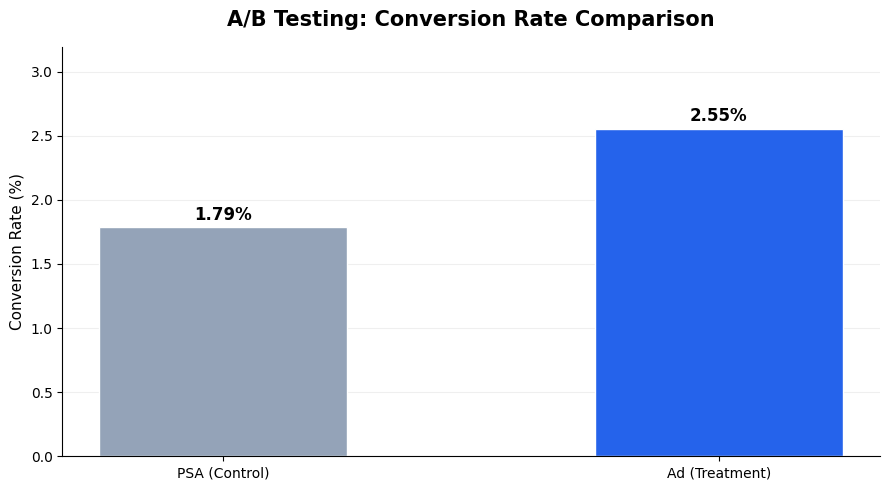

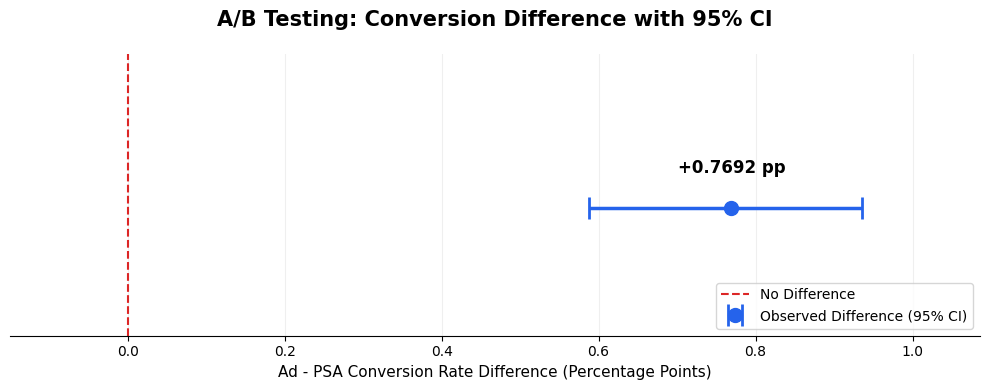

BLOCK 5: VISUALIZATION SUMMARY
Ad Conversion Rate: 2.5547%
PSA Conversion Rate: 1.7854%
Absolute Difference: +0.7692 percentage points
Relative Conversion Lift: +43.09%
95% Confidence Interval: [0.5873, 0.9360] percentage points
P-value: 1.70528071616e-13

Both charts generated and saved successfully!

Saved files:
1. /kaggle/working/conversion_comparison.png
2. /kaggle/working/conversion_confidence_interval.png


In [7]:

# ============================================================
# BLOCK 5: A/B TEST DATA VISUALIZATION
# Marketing A/B Testing - Conversion Analysis
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# CHART 1: AD VS PSA CONVERSION RATE
# ------------------------------------------------------------

groups = ["PSA (Control)", "Ad (Treatment)"]

rates = [
    group_summary.loc["psa", "conversion_rate_pct"],
    group_summary.loc["ad", "conversion_rate_pct"]
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    groups,
    rates,
    color=["#94A3B8", "#2563EB"],
    width=0.5,
    edgecolor="white"
)

# Add percentage labels above bars
for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.06,
        f"{rate:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "A/B Testing: Conversion Rate Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Conversion Rate (%)", fontsize=11)
ax.set_ylim(0, max(rates) * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/conversion_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# CHART 2: CONVERSION DIFFERENCE WITH 95% CONFIDENCE INTERVAL
# ------------------------------------------------------------

# Calculate observed difference in percentage points
difference_pp = (ad_rate - psa_rate) * 100

# Convert confidence interval to percentage points
lower_pp = ci_low * 100
upper_pp = ci_high * 100

# Error bar distances from the observed difference
lower_error = difference_pp - lower_pp
upper_error = upper_pp - difference_pp

# Correct shape: (2, 1)
x_error = np.array([
    [lower_error],
    [upper_error]
])

fig, ax = plt.subplots(figsize=(10, 4))

ax.errorbar(
    x=[difference_pp],
    y=[0],
    xerr=x_error,
    fmt="o",
    color="#2563EB",
    ecolor="#2563EB",
    markersize=10,
    capsize=8,
    elinewidth=2.5,
    capthick=2,
    label="Observed Difference (95% CI)"
)

# Reference line at zero difference
ax.axvline(
    x=0,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label="No Difference"
)

# Label observed difference
ax.annotate(
    f"+{difference_pp:.4f} pp",
    xy=(difference_pp, 0),
    xytext=(0, 25),
    textcoords="offset points",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "A/B Testing: Conversion Difference with 95% CI",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Ad - PSA Conversion Rate Difference (Percentage Points)",
    fontsize=11
)

ax.set_yticks([])
ax.set_ylim(-0.5, 0.6)

# Ensure zero and the entire confidence interval are visible
ax.set_xlim(
    min(0, lower_pp) - 0.15,
    max(0, upper_pp) + 0.15
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/conversion_confidence_interval.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print("BLOCK 5: VISUALIZATION SUMMARY")
print("=" * 55)

print(f"Ad Conversion Rate: {ad_rate * 100:.4f}%")
print(f"PSA Conversion Rate: {psa_rate * 100:.4f}%")

print(
    f"Absolute Difference: "
    f"{difference_pp:+.4f} percentage points"
)

print(
    f"Relative Conversion Lift: "
    f"{relative_lift:+.2f}%"
)

print(
    f"95% Confidence Interval: "
    f"[{lower_pp:.4f}, {upper_pp:.4f}] percentage points"
)

print(f"P-value: {p_value:.12g}")

print("\nBoth charts generated and saved successfully!")

print("\nSaved files:")
print("1. /kaggle/working/conversion_comparison.png")
print("2. /kaggle/working/conversion_confidence_interval.png")


## 6. Experiment Quality Assessment

In [9]:

# ============================================================
# BLOCK 6: EXPERIMENT QUALITY & RELIABILITY CHECK
# Marketing A/B Testing - Business Decision Analysis
# ============================================================

import pandas as pd
import numpy as np

print("=" * 60)
print("BLOCK 6: EXPERIMENT QUALITY ASSESSMENT")
print("=" * 60)

# ------------------------------------------------------------
# 1. GROUP ALLOCATION ANALYSIS
# ------------------------------------------------------------

group_counts = df["test group"].value_counts()
total_users = len(df)

print("\n1. GROUP ALLOCATION")
print("-" * 40)

for group in ["ad", "psa"]:
    count = group_counts.get(group, 0)
    percentage = (count / total_users) * 100

    print(f"{group.upper()} Group")
    print(f"  Total Users: {count:,}")
    print(f"  Allocation: {percentage:.2f}%")

print("\nObservation:")
print("The experiment groups are highly unequal.")
print("An unequal split is not automatically an error.")
print("The intended allocation ratio must be confirmed")
print("before diagnosing Sample Ratio Mismatch (SRM).")


# ------------------------------------------------------------
# 2. DATA QUALITY CHECK
# ------------------------------------------------------------

print("\n2. DATA QUALITY VALIDATION")
print("-" * 40)

missing_values = int(df.isnull().sum().sum())
duplicate_users = int(df["user id"].duplicated().sum())

invalid_groups = int(
    (~df["test group"].isin(["ad", "psa"])).sum()
)

invalid_conversions = int(
    (~df["converted"].isin([True, False])).sum()
)

negative_exposures = int(
    (df["total ads"] < 0).sum()
)

invalid_hours = int(
    (~df["most ads hour"].between(0, 23)).sum()
)

valid_days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

invalid_days = int(
    (~df["most ads day"].isin(valid_days)).sum()
)

quality_results = {
    "Missing Values": missing_values,
    "Duplicate User IDs": duplicate_users,
    "Invalid Groups": invalid_groups,
    "Invalid Conversion Values": invalid_conversions,
    "Negative Exposure Counts": negative_exposures,
    "Invalid Hours": invalid_hours,
    "Invalid Days": invalid_days
}

for check, result in quality_results.items():
    print(f"{check}: {result}")

total_quality_flags = sum(quality_results.values())

print("\nData Quality Result:")

if total_quality_flags == 0:
    print("PASS: No basic data-quality problems detected.")
else:
    print("WARNING: Data-quality problems detected.")


# ------------------------------------------------------------
# 3. AD EXPOSURE DISTRIBUTION
# ------------------------------------------------------------

print("\n3. EXPOSURE ANALYSIS")
print("-" * 40)

exposure_summary = df.groupby("test group")[
    "total ads"
].agg(["count", "mean", "median", "min", "max"])

print(exposure_summary.round(2))

print("\nInterpretation:")
print("Compare the average and median exposure")
print("between Ad and PSA groups.")
print("Exposure is a post-assignment variable,")
print("so it cannot independently verify randomization.")


# ------------------------------------------------------------
# 4. ZERO-EXPOSURE CHECK
# ------------------------------------------------------------

print("\n4. ZERO-EXPOSURE CHECK")
print("-" * 40)

zero_exposure = df.groupby("test group")[
    "total ads"
].apply(lambda x: (x == 0).sum())

print(zero_exposure)


# ------------------------------------------------------------
# 5. EXPERIMENT RELIABILITY ASSESSMENT
# ------------------------------------------------------------

print("\n5. EXPERIMENT RELIABILITY")
print("-" * 40)

print(f"Observed Conversion Lift: {relative_lift:+.2f}%")
print(f"P-value: {p_value:.12g}")

if p_value < 0.05:
    print("Statistical Result: Significant Difference")
else:
    print("Statistical Result: Not Significant")

print("\nIMPORTANT LIMITATIONS:")
print("1. Intended group allocation is unknown.")
print("2. Random assignment is not independently verified.")
print("3. Campaign costs and revenue are unavailable.")
print("4. Statistical significance does not prove causation.")
print("5. Profitability cannot be calculated from this data.")


# ------------------------------------------------------------
# 6. PRELIMINARY BUSINESS RECOMMENDATION
# ------------------------------------------------------------

print("\n6. PRELIMINARY BUSINESS RECOMMENDATION")
print("-" * 40)

if p_value < 0.05 and ad_rate > psa_rate:
    print("RESULT: Ad group performed significantly better.")
    print("RECOMMENDATION: Investigate controlled scaling.")
    print("First validate randomization, group allocation,")
    print("and campaign economics.")
else:
    print("RESULT: Insufficient evidence of Ad superiority.")
    print("RECOMMENDATION: Investigate or run further tests.")

print("\n" + "=" * 60)
print("BLOCK 6 COMPLETED SUCCESSFULLY!")
print("=" * 60)


BLOCK 6: EXPERIMENT QUALITY ASSESSMENT

1. GROUP ALLOCATION
----------------------------------------
AD Group
  Total Users: 564,577
  Allocation: 96.00%
PSA Group
  Total Users: 23,524
  Allocation: 4.00%

Observation:
The experiment groups are highly unequal.
An unequal split is not automatically an error.
The intended allocation ratio must be confirmed
before diagnosing Sample Ratio Mismatch (SRM).

2. DATA QUALITY VALIDATION
----------------------------------------
Missing Values: 0
Duplicate User IDs: 0
Invalid Groups: 0
Invalid Conversion Values: 0
Negative Exposure Counts: 0
Invalid Hours: 0
Invalid Days: 0

Data Quality Result:
PASS: No basic data-quality problems detected.

3. EXPOSURE ANALYSIS
----------------------------------------
             count   mean  median  min   max
test group                                  
ad          564577  24.82    13.0    1  2065
psa          23524  24.76    12.0    1   907

Interpretation:
Compare the average and median exposure
between A

## 7. Business Recommendations and Conclusion

In [10]:

# ============================================================
# BLOCK 7: FINAL BUSINESS INSIGHTS & EXECUTIVE SUMMARY
# Project: Marketing A/B Testing & Business Decision Analysis
# Analyst: Azizul Hakim
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

# ------------------------------------------------------------
# 1. CALCULATE FINAL PERFORMANCE METRICS
# ------------------------------------------------------------

results = df.groupby("test group")["converted"].agg(
    total_users="count",
    conversions="sum"
)

ad_users = int(results.loc["ad", "total_users"])
psa_users = int(results.loc["psa", "total_users"])

ad_conversions = int(results.loc["ad", "conversions"])
psa_conversions = int(results.loc["psa", "conversions"])

total_users = ad_users + psa_users

ad_rate = ad_conversions / ad_users
psa_rate = psa_conversions / psa_users

absolute_lift = (ad_rate - psa_rate) * 100
relative_lift = ((ad_rate / psa_rate) - 1) * 100

# ------------------------------------------------------------
# 2. STATISTICAL HYPOTHESIS TESTING
# ------------------------------------------------------------

z_stat, p_value = proportions_ztest(
    count=[ad_conversions, psa_conversions],
    nobs=[ad_users, psa_users],
    alternative="two-sided"
)

ci_low, ci_high = confint_proportions_2indep(
    count1=ad_conversions,
    nobs1=ad_users,
    count2=psa_conversions,
    nobs2=psa_users,
    compare="diff",
    method="newcomb",
    alpha=0.05
)

ci_low_pp = ci_low * 100
ci_high_pp = ci_high * 100

# ------------------------------------------------------------
# 3. DATA QUALITY AND EXPERIMENT RELIABILITY
# ------------------------------------------------------------

missing_values = int(df.isnull().sum().sum())

duplicate_users = int(
    df["user id"].duplicated().sum()
)

ad_allocation = (ad_users / total_users) * 100
psa_allocation = (psa_users / total_users) * 100

exposure_summary = df.groupby("test group")[
    "total ads"
].agg(["mean", "median"])

# ------------------------------------------------------------
# 4. BUSINESS DECISION FRAMEWORK
# ------------------------------------------------------------

if p_value < 0.05 and ad_rate > psa_rate:

    statistical_finding = (
        "Statistically significant positive difference"
    )

    business_decision = "VALIDATE BEFORE SCALING"

    recommendation = (
        "The Ad group achieved a significantly higher "
        "observed conversion rate. However, the company "
        "should verify experimental randomisation, "
        "planned allocation and campaign economics "
        "before expanding advertising investment."
    )

elif p_value < 0.05 and ad_rate < psa_rate:

    statistical_finding = (
        "Statistically significant negative difference"
    )

    business_decision = "DO NOT SCALE YET"

    recommendation = (
        "The Ad group performed significantly worse. "
        "Investigate campaign design and experiment "
        "validity before further investment."
    )

else:

    statistical_finding = (
        "No statistically significant difference"
    )

    business_decision = "FURTHER TESTING REQUIRED"

    recommendation = (
        "The available evidence does not establish "
        "a significant conversion difference. "
        "Review experiment design, statistical power "
        "and potential follow-up tests."
    )

# ------------------------------------------------------------
# 5. EXECUTIVE SUMMARY REPORT
# ------------------------------------------------------------

report = f"""
# Marketing A/B Testing:
# Conversion Analysis & Business Decision-Making

**Analyst:** Azizul Hakim

**Project Type:** Independent Data Analytics Project

**Tools:** Python, Pandas, Statsmodels, Matplotlib

**Dataset:** Marketing A/B Testing - Kaggle

---

## 1. Business Problem

This project evaluates whether users shown a product
advertisement achieved higher conversion rates than
users shown a Public Service Announcement (PSA).

The objective is to support evidence-based decisions
about advertising performance and future investment.

## 2. Dataset Overview

| Metric | Value |
|---|---:|
| Total Users | {total_users:,} |
| Ad Group Users | {ad_users:,} |
| PSA Group Users | {psa_users:,} |
| Ad Conversions | {ad_conversions:,} |
| PSA Conversions | {psa_conversions:,} |
| Missing Values | {missing_values} |
| Duplicate User IDs | {duplicate_users} |

## 3. Conversion Performance

| Metric | Result |
|---|---:|
| Ad Conversion Rate | {ad_rate*100:.4f}% |
| PSA Conversion Rate | {psa_rate*100:.4f}% |
| Absolute Difference | {absolute_lift:+.4f} pp |
| Relative Conversion Lift | {relative_lift:+.2f}% |

### Key Finding

The Ad group demonstrated a higher observed
conversion rate than the PSA group.

The relative conversion lift was
**{relative_lift:+.2f}%**.

This is an observed association, not independently
verified causal uplift.

## 4. Statistical Analysis

**Null Hypothesis (H0):**
The two groups have equal conversion rates.

**Alternative Hypothesis (H1):**
The conversion rates differ.

| Statistical Metric | Result |
|---|---:|
| Z-statistic | {z_stat:.4f} |
| P-value | {p_value:.4e} |
| Significance Level | 0.05 |
| 95% CI Lower | {ci_low_pp:+.4f} pp |
| 95% CI Upper | {ci_high_pp:+.4f} pp |

**Statistical Finding:**
{statistical_finding}.

The two-sided test finds a statistically significant
difference when the p-value is below 0.05.

The confidence interval describes uncertainty
in the estimated conversion-rate difference,
subject to the statistical model assumptions.

## 5. Experiment Quality Assessment

### Group Allocation

- Ad allocation: {ad_allocation:.2f}%
- PSA allocation: {psa_allocation:.2f}%

The observed allocation is unequal.

However, the intended allocation ratio is unknown.
Therefore, Sample Ratio Mismatch (SRM) cannot
be confirmed from these counts alone.

### Advertisement Exposure

- Ad average exposure:
  {exposure_summary.loc["ad", "mean"]:.2f}

- PSA average exposure:
  {exposure_summary.loc["psa", "mean"]:.2f}

- Ad median exposure:
  {exposure_summary.loc["ad", "median"]:.2f}

- PSA median exposure:
  {exposure_summary.loc["psa", "median"]:.2f}

Exposure is recorded after assignment and does
not independently confirm randomisation quality.

### Data Reliability

- No missing values detected.
- No duplicate user IDs detected.
- Basic dataset validation passed.
- Original randomisation cannot be verified.
- Planned group allocation is unavailable.
- Advertising costs and revenue are unavailable.

## 6. Business Recommendation

### Decision: {business_decision}

{recommendation}

### Recommended Next Actions

1. Verify the planned experiment allocation
   and random assignment process.

2. Confirm experiment tracking and eligibility
   rules before interpreting causal effects.

3. Obtain advertising costs, revenue per
   conversion and customer value information.

4. Calculate incremental profit and return
   on advertising investment where possible.

5. If experiment validity and financial
   performance are confirmed, consider
   a limited monitored rollout.

6. Track conversion rate, acquisition cost
   and profitability during the rollout.

## 7. Limitations

- Randomisation procedures are not documented.
- Group allocation is highly unequal.
- The intended allocation ratio is unknown.
- Campaign financial data are unavailable.
- Profitability cannot be calculated.
- Statistical significance alone does not
  establish causality or financial success.

## 8. Final Conclusion

The Ad group achieved a conversion rate of
**{ad_rate*100:.4f}%**, compared with
**{psa_rate*100:.4f}%** for the PSA group.

The relative observed conversion lift was
**{relative_lift:+.2f}%**, with a statistically
significant difference (p = {p_value:.4e}).

These findings support further evaluation
of the advertising strategy.

However, experimental design validation and
campaign profitability analysis are required
before recommending full-scale investment.

**Final Business Decision: {business_decision}**

---

*Independent portfolio analysis using a
publicly available Kaggle dataset.*
"""

# ------------------------------------------------------------
# 6. DISPLAY PROFESSIONAL REPORT
# ------------------------------------------------------------

display(Markdown(report))

# ------------------------------------------------------------
# 7. EXPORT EXECUTIVE SUMMARY
# ------------------------------------------------------------

output_dir = Path("/kaggle/working")
output_dir.mkdir(parents=True, exist_ok=True)

report_file = (
    output_dir / "ab_testing_executive_summary.md"
)

report_file.write_text(
    report,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. EXPORT METRICS AS CSV
# ------------------------------------------------------------

metrics = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Ad Group Users",
        "PSA Group Users",
        "Ad Conversions",
        "PSA Conversions",
        "Ad Conversion Rate (%)",
        "PSA Conversion Rate (%)",
        "Absolute Lift (pp)",
        "Relative Lift (%)",
        "Z Statistic",
        "P Value",
        "95% CI Lower (pp)",
        "95% CI Upper (pp)"
    ],

    "Value": [
        total_users,
        ad_users,
        psa_users,
        ad_conversions,
        psa_conversions,
        ad_rate * 100,
        psa_rate * 100,
        absolute_lift,
        relative_lift,
        z_stat,
        p_value,
        ci_low_pp,
        ci_high_pp
    ]
})

metrics_file = (
    output_dir / "ab_testing_final_metrics.csv"
)

metrics.to_csv(
    metrics_file,
    index=False
)

# ------------------------------------------------------------
# 9. FINAL OUTPUT
# ------------------------------------------------------------

print("=" * 60)
print("BLOCK 7 COMPLETED SUCCESSFULLY!")
print("=" * 60)

print(f"\nTotal Users: {total_users:,}")
print(f"Ad Conversion Rate: {ad_rate*100:.4f}%")
print(f"PSA Conversion Rate: {psa_rate*100:.4f}%")
print(f"Relative Lift: {relative_lift:+.2f}%")
print(f"P-value: {p_value:.4e}")

print("\nFINAL BUSINESS DECISION:")
print(business_decision)

print("\nFiles Saved Successfully:")
print("1. ab_testing_executive_summary.md")
print("2. ab_testing_final_metrics.csv")

print("\nPROJECT ANALYSIS COMPLETED!")



# Marketing A/B Testing:
# Conversion Analysis & Business Decision-Making

**Analyst:** Azizul Hakim

**Project Type:** Independent Data Analytics Project

**Tools:** Python, Pandas, Statsmodels, Matplotlib

**Dataset:** Marketing A/B Testing - Kaggle

---

## 1. Business Problem

This project evaluates whether users shown a product
advertisement achieved higher conversion rates than
users shown a Public Service Announcement (PSA).

The objective is to support evidence-based decisions
about advertising performance and future investment.

## 2. Dataset Overview

| Metric | Value |
|---|---:|
| Total Users | 588,101 |
| Ad Group Users | 564,577 |
| PSA Group Users | 23,524 |
| Ad Conversions | 14,423 |
| PSA Conversions | 420 |
| Missing Values | 0 |
| Duplicate User IDs | 0 |

## 3. Conversion Performance

| Metric | Result |
|---|---:|
| Ad Conversion Rate | 2.5547% |
| PSA Conversion Rate | 1.7854% |
| Absolute Difference | +0.7692 pp |
| Relative Conversion Lift | +43.09% |

### Key Finding

The Ad group demonstrated a higher observed
conversion rate than the PSA group.

The relative conversion lift was
**+43.09%**.

This is an observed association, not independently
verified causal uplift.

## 4. Statistical Analysis

**Null Hypothesis (H0):**
The two groups have equal conversion rates.

**Alternative Hypothesis (H1):**
The conversion rates differ.

| Statistical Metric | Result |
|---|---:|
| Z-statistic | 7.3701 |
| P-value | 1.7053e-13 |
| Significance Level | 0.05 |
| 95% CI Lower | +0.5873 pp |
| 95% CI Upper | +0.9360 pp |

**Statistical Finding:**
Statistically significant positive difference.

The two-sided test finds a statistically significant
difference when the p-value is below 0.05.

The confidence interval describes uncertainty
in the estimated conversion-rate difference,
subject to the statistical model assumptions.

## 5. Experiment Quality Assessment

### Group Allocation

- Ad allocation: 96.00%
- PSA allocation: 4.00%

The observed allocation is unequal.

However, the intended allocation ratio is unknown.
Therefore, Sample Ratio Mismatch (SRM) cannot
be confirmed from these counts alone.

### Advertisement Exposure

- Ad average exposure:
  24.82

- PSA average exposure:
  24.76

- Ad median exposure:
  13.00

- PSA median exposure:
  12.00

Exposure is recorded after assignment and does
not independently confirm randomisation quality.

### Data Reliability

- No missing values detected.
- No duplicate user IDs detected.
- Basic dataset validation passed.
- Original randomisation cannot be verified.
- Planned group allocation is unavailable.
- Advertising costs and revenue are unavailable.

## 6. Business Recommendation

### Decision: VALIDATE BEFORE SCALING

The Ad group achieved a significantly higher observed conversion rate. However, the company should verify experimental randomisation, planned allocation and campaign economics before expanding advertising investment.

### Recommended Next Actions

1. Verify the planned experiment allocation
   and random assignment process.

2. Confirm experiment tracking and eligibility
   rules before interpreting causal effects.

3. Obtain advertising costs, revenue per
   conversion and customer value information.

4. Calculate incremental profit and return
   on advertising investment where possible.

5. If experiment validity and financial
   performance are confirmed, consider
   a limited monitored rollout.

6. Track conversion rate, acquisition cost
   and profitability during the rollout.

## 7. Limitations

- Randomisation procedures are not documented.
- Group allocation is highly unequal.
- The intended allocation ratio is unknown.
- Campaign financial data are unavailable.
- Profitability cannot be calculated.
- Statistical significance alone does not
  establish causality or financial success.

## 8. Final Conclusion

The Ad group achieved a conversion rate of
**2.5547%**, compared with
**1.7854%** for the PSA group.

The relative observed conversion lift was
**+43.09%**, with a statistically
significant difference (p = 1.7053e-13).

These findings support further evaluation
of the advertising strategy.

However, experimental design validation and
campaign profitability analysis are required
before recommending full-scale investment.

**Final Business Decision: VALIDATE BEFORE SCALING**

---

*Independent portfolio analysis using a
publicly available Kaggle dataset.*


BLOCK 7 COMPLETED SUCCESSFULLY!

Total Users: 588,101
Ad Conversion Rate: 2.5547%
PSA Conversion Rate: 1.7854%
Relative Lift: +43.09%
P-value: 1.7053e-13

FINAL BUSINESS DECISION:
VALIDATE BEFORE SCALING

Files Saved Successfully:
1. ab_testing_executive_summary.md
2. ab_testing_final_metrics.csv

PROJECT ANALYSIS COMPLETED!
